# Shipment Delay Insight — Complete Project Notebook


In [ ]:
# 1. Imports and setup
import os, glob, warnings, zipfile
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
BASE_DIR = "/content"
OUTPUT_DIR = "/content/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Setup complete.")
print("Files currently in /content:")
print(os.listdir(BASE_DIR)[:30])




Setup complete.
Files currently in /content:
['.config', 'shipments.csv', 'output', 'routes.csv', 'carriers.csv', 'README.txt', 'weather.csv', 'events.csv', 'Shipment_Delay_Project_Outputs.zip', 'sample_data']


## 2. Load the five datasets
The loader first looks for each CSV in `/content`. If your files are in a subfolder, update `BASE_DIR` above to that folder.

In [ ]:
required_files = ["shipments.csv", "routes.csv", "carriers.csv", "events.csv", "weather.csv"]
missing_files = [f for f in required_files if not os.path.exists(os.path.join(BASE_DIR, f))]

if missing_files:
    print("Could not find:", missing_files)
    print("Upload these files to Colab's Files panel, or change BASE_DIR to the folder containing them.")
else:
    shipments = pd.read_csv(os.path.join(BASE_DIR, "shipments.csv"))
    routes = pd.read_csv(os.path.join(BASE_DIR, "routes.csv"))
    carriers = pd.read_csv(os.path.join(BASE_DIR, "carriers.csv"))
    events = pd.read_csv(os.path.join(BASE_DIR, "events.csv"))
    weather = pd.read_csv(os.path.join(BASE_DIR, "weather.csv"))

    datasets = {
        "Shipments": shipments, "Routes": routes, "Carriers": carriers,
        "Events": events, "Weather": weather
    }
    for name, df in datasets.items():
        print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
        display(df.head(3))


Shipments: 1,203 rows × 13 columns


,shipment_id,origin,destination,route_name,carrier,service_level,dispatch_datetime,promised_delivery_date,actual_delivery_date,shipment_type,dispatch_period,weather_id,hub_id
0,SHP00001,Coimbatore,Bengaluru,Bengaluru-Coimbatore,Carrier B,Express,2026-04-14 19:00:00,2026-04-16,2026-04-17,Parcel,Evening,W00001,HUB07
1,SHP00002,Kochi,Coimbatore,Coimbatore-Kochi,Carrier C,Economy,2026-05-25 09:00:00,2026-05-28,2026-05-29,Parcel,Morning,W00002,HUB05
2,SHP00003,Bengaluru,Chennai,Bengaluru-Chennai,Carrier C,Standard,2026-05-03 10:00:00,2026-05-06,2026-05-08,Bulk,Morning,W00003,HUB03


Routes: 15 rows × 4 columns


,route_name,distance_km,route_type,number_of_hubs
0,Bengaluru-Coimbatore,376,Highway,1
1,Coimbatore-Kochi,621,Highway,1
2,Bengaluru-Chennai,684,Highway,2


Carriers: 4 rows × 3 columns


,carrier,service_level,carrier_region
0,Carrier A,Mixed,South
1,Carrier B,Mixed,South
2,Carrier C,Mixed,South


Events: 1,200 rows × 7 columns


,event_id,shipment_id,hub_id,hub_arrival_datetime,hub_departure_datetime,exception_code,transit_duration_hours
0,EV00001,SHP00001,HUB07,2026-04-16 00:49:04,2026-04-16 14:04:12,NaN,13.25
1,EV00002,SHP00002,HUB05,2026-05-27 05:12:09,2026-05-28 00:50:53,NaN,19.65
2,EV00003,SHP00003,HUB03,2026-05-05 14:53:48,2026-05-06 14:24:23,NaN,23.51


Weather: 1,200 rows × 4 columns


,weather_id,rainfall,visibility,storm_flag
0,W00001,Light,Poor,0
1,W00002,NaN,Good,0
2,W00003,Heavy,Good,0


## 3. Data-quality audit
This section reports missing values, exact duplicate rows, duplicate shipment IDs, route-name variations, and potentially invalid transit durations before cleaning.

In [18]:
# Ensure datasets exist before proceeding
assert all(name in globals() for name in ["shipments", "routes", "carriers", "events", "weather"]), \
    "Please upload all five CSV files and run the loading cell first."

quality_rows = []
for name, df in datasets.items():
    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum())
    })
quality_summary = pd.DataFrame(quality_rows)
display(quality_summary)

print("\nMissing values by column")
for name, df in datasets.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    print(f"\n{name}")
    display(miss.rename("missing_count").to_frame() if len(miss) else pd.DataFrame({"status":["No missing values"]}))

if "shipment_id" in shipments:
    print("Duplicate shipment_id rows:", int(shipments["shipment_id"].duplicated(keep=False).sum()))
    display(shipments[shipments["shipment_id"].duplicated(keep=False)].sort_values("shipment_id").head(15))
if "route_name" in shipments:
    print("\nShipment route names (first 30 unique values):")
    print(sorted(shipments["route_name"].dropna().astype(str).unique())[:30])
if "transit_duration_hours" in events:
    vals = pd.to_numeric(events["transit_duration_hours"], errors="coerce")
    print("\nTransit duration values that are missing, non-numeric, or <= 0:", int((vals.isna() | (vals <= 0)).sum()))


,dataset,rows,columns,exact_duplicate_rows,missing_cells
0,Shipments,1203,13,3,14
1,Routes,15,4,0,0
2,Carriers,4,3,0,0
3,Events,1200,7,0,858
4,Weather,1200,4,0,666



Missing values by column

Shipments


,missing_count
actual_delivery_date,14



Routes


,status
0,No missing values


...


Weather


,missing_count
rainfall,666


Duplicate shipment_id rows: 22


,shipment_id,origin,destination,route_name,carrier,service_level,dispatch_datetime,promised_delivery_date,actual_delivery_date,shipment_type,dispatch_period,weather_id,hub_id
4,SHP00005,Chennai,Kochi,Chennai-Kochi,Carrier A,Standard,2026-04-20 10:00:00,2026-04-22,2026-04-24,Fragile,Morning,W00005,HUB08
1200,SHP00005,Chennai,Kochi,Chennai-Kochi,Carrier A,Standard,2026-04-20 10:00:00,2026-04-22,2026-04-24,Fragile,Morning,W00005,HUB08
8,SHP00009,Coimbatore,Bengaluru,Bengaluru-Coimbatore,Carrier C,Economy,2026-04-08 06:00:00,2026-04-10,2026-04-12,Fragile,Morning,W00009,HUB05
82,SHP00009,Chennai,Hyderabad,Chennai-Hyderabad,Carrier C,Standard,2026-03-29 18:00:00,2026-04-02,2026-04-04,Perishable,Evening,W00083,HUB04
383,SHP00010,Hyderabad,Bengaluru,Bengaluru-Hyderabad,Carrier A,Standard,2026-01-03 07:00:00,2026-01-06,2026-01-07,Parcel,Morning,W00384,HUB02
9,SHP00010,Hyderabad,Chennai,Chennai-Hyderabad,Carrier A,Economy,2026-04-12 06:00:00,2026-04-15,2026-04-17,Perishable,Morning,W00010,HUB07
20,SHP00021,Kochi,Chennai,Chennai-Kochi,Carrier A,Standard,2026-05-08 13:00:00,2026-05-10,2026-05-11,Bulk,Afternoon,W00021,HUB06
1201,SHP00021,Kochi,Chennai,Chennai-Kochi,Carrier A,Standard,2026-05-08 13:00:00,2026-05-10,2026-05-11,Bulk,Afternoon,W00021,HUB06
754,SHP00058,Hyderabad,Bengaluru,Bengaluru-Hyderabad,Carrier A,Standard,2026-01-16 12:00:00,2026-01-20,2026-01-19,Perishable,Afternoon,W00755,HUB06
57,SHP00058,Hyderabad,Madurai,Hyderabad-Madurai,Carrier B,Standard,2026-03-10 09:00:00,2026-03-13,2026-03-14,Parcel,Morning,W00058,HUB06



Shipment route names (first 30 unique values):
['Bengaluru-Chennai', 'Bengaluru-Chennai ', 'Bengaluru-Coimbatore', 'Bengaluru-Coimbatore ', 'Bengaluru-Hyderabad', 'Bengaluru-Kochi', 'Bengaluru-Madurai', 'Chennai-Coimbatore', 'Chennai-Hyderabad', 'Chennai-Kochi', 'Chennai-Madurai', 'Coimbatore-Hyderabad', 'Coimbatore-Kochi', 'Coimbatore-Kochi ', 'Coimbatore-Madurai', 'Hyderabad-Kochi', 'Hyderabad-Kochi ', 'Hyderabad-Madurai', 'Kochi-Madurai']

Transit duration values that are missing, non-numeric, or <= 0: 2


In [ ]:
# Work on copies so original imported data stays available
ship_clean = shipments.copy()
routes_clean = routes.copy()
carriers_clean = carriers.copy()
events_clean = events.copy()
weather_clean = weather.copy()

# Strip whitespace from text columns
for df in [ship_clean, routes_clean, carriers_clean, events_clean, weather_clean]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

# Parse dates
for col in ["dispatch_datetime", "promised_delivery_date", "actual_delivery_date"]:
    if col in ship_clean:
        ship_clean[col] = pd.to_datetime(ship_clean[col], errors="coerce")
for col in ["hub_arrival_datetime", "hub_departure_datetime"]:
    if col in events_clean:
        events_clean[col] = pd.to_datetime(events_clean[col], errors="coerce")

# Remove exact duplicates
before_exact = {k: len(v) for k, v in [
    ("shipments", ship_clean), ("routes", routes_clean), ("carriers", carriers_clean),
    ("events", events_clean), ("weather", weather_clean)
]}
ship_clean = ship_clean.drop_duplicates()
routes_clean = routes_clean.drop_duplicates()
carriers_clean = carriers_clean.drop_duplicates()
events_clean = events_clean.drop_duplicates()
weather_clean = weather_clean.drop_duplicates()

# Normalize route labels using case/space/hyphen cleanup, then map to canonical route table when possible
def normalize_route(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().replace("–", "-").replace("—", "-")
    parts = [p.strip() for p in s.split("-")]
    if len(parts) == 2:
        # Route is treated as a pair of locations; sort alphabetically so direction variants match
        return "-".join(sorted(parts, key=lambda x: x.casefold()))
    return " ".join(s.split())

# Build canonical mapping from routes table; match unordered origin/destination pair if route name is inconsistent
def route_key(value):
    if pd.isna(value): return np.nan
    parts = [p.strip() for p in str(value).replace("–","-").replace("—","-").split("-")]
    if len(parts) == 2:
        return tuple(sorted([p.casefold() for p in parts]))
    return ("raw", str(value).strip().casefold())

route_lookup = {}
for rn in routes_clean.get("route_name", pd.Series(dtype=object)).dropna().unique():
    route_lookup[route_key(rn)] = rn

if "route_name" in ship_clean:
    ship_clean["route_name_original"] = ship_clean["route_name"]
    ship_clean["route_key"] = ship_clean["route_name"].map(route_key)
    ship_clean["route_name"] = ship_clean["route_key"].map(route_lookup).fillna(ship_clean["route_name"].map(normalize_route))
    ship_clean = ship_clean.drop(columns=["route_key"])

# Remove duplicate shipment IDs: prefer actual-delivery-date present, then earliest dispatch row
if "shipment_id" in ship_clean:
    ship_clean["_has_actual"] = ship_clean["actual_delivery_date"].notna() if "actual_delivery_date" in ship_clean else False
    if "dispatch_datetime" in ship_clean:
        ship_clean = ship_clean.sort_values(["_has_actual", "dispatch_datetime"], ascending=[False, True])
    else:
        ship_clean = ship_clean.sort_values(["_has_actual"], ascending=[False])
    ship_clean = ship_clean.drop_duplicates(subset=["shipment_id"], keep="first").drop(columns=["_has_actual"])

# Numeric transit duration; invalid <= 0 becomes missing
if "transit_duration_hours" in events_clean:
    events_clean["transit_duration_hours"] = pd.to_numeric(events_clean["transit_duration_hours"], errors="coerce")
    events_clean.loc[events_clean["transit_duration_hours"] <= 0, "transit_duration_hours"] = np.nan

# Normalize exception code blanks and common missing tokens
if "exception_code" in events_clean:
    events_clean["exception_code"] = events_clean["exception_code"].replace(r"^\s*$", np.nan, regex=True)

# Deduplicate lookup tables by their natural keys
if "route_name" in routes_clean: routes_clean = routes_clean.drop_duplicates("route_name", keep="first")
if "carrier" in carriers_clean: carriers_clean = carriers_clean.drop_duplicates("carrier", keep="first")
if "weather_id" in weather_clean: weather_clean = weather_clean.drop_duplicates("weather_id", keep="first")

print("Rows before/after exact duplicate removal:")
print(before_exact)
print({
    "shipments_clean": ship_clean.shape,
    "routes_clean": routes_clean.shape,
    "carriers_clean": carriers_clean.shape,
    "events_clean": events_clean.shape,
    "weather_clean": weather_clean.shape
})
print("Unique shipment IDs after cleaning:", ship_clean["shipment_id"].nunique() if "shipment_id" in ship_clean else "N/A")


Rows before/after exact duplicate removal:
{'shipments': 1203, 'routes': 15, 'carriers': 4, 'events': 1200, 'weather': 1200}
{'shipments_clean': (1192, 14), 'routes_clean': (15, 4), 'carriers_clean': (4, 3), 'events_clean': (1200, 7), 'weather_clean': (1200, 4)}
Unique shipment IDs after cleaning: 1192


## 5. Combine data safely



In [ ]:
# Aggregate events per shipment
event_agg = events_clean.copy()
if "exception_code" in event_agg:
    event_agg["has_exception"] = event_agg["exception_code"].notna().astype(int)
else:
    event_agg["has_exception"] = 0

agg_dict = {}
if "transit_duration_hours" in event_agg:
    agg_dict["transit_duration_hours"] = ["mean", "max", "sum", "count"]
if "has_exception" in event_agg:
    agg_dict["has_exception"] = ["max", "sum"]
if "hub_id" in event_agg:
    agg_dict["hub_id"] = pd.Series.nunique

if agg_dict:
    event_summary = event_agg.groupby("shipment_id").agg(agg_dict)
    event_summary.columns = [
        "_".join(str(x) for x in col if x) if isinstance(col, tuple) else str(col)
        for col in event_summary.columns
    ]
    event_summary = event_summary.reset_index()
else:
    event_summary = pd.DataFrame({"shipment_id": ship_clean["shipment_id"].dropna().unique()})

# Friendly column names
event_summary = event_summary.rename(columns={
    "transit_duration_hours_mean": "avg_transit_duration_hours",
    "transit_duration_hours_max": "max_transit_duration_hours",
    "transit_duration_hours_sum": "total_transit_duration_hours",
    "transit_duration_hours_count": "valid_transit_event_count",
    "has_exception_max": "any_hub_exception",
    "has_exception_sum": "hub_exception_count",
    "hub_id_nunique": "unique_hubs_visited"
})

master = ship_clean.copy()
if "route_name" in master and "route_name" in routes_clean:
    master = master.merge(routes_clean, on="route_name", how="left", suffixes=("", "_route"))
if "carrier" in master and "carrier" in carriers_clean:
    # Carrier table may also include service_level; avoid duplicate service_level columns
    carrier_lookup = carriers_clean.drop(columns=["service_level"], errors="ignore")
    master = master.merge(carrier_lookup, on="carrier", how="left")
if "weather_id" in master and "weather_id" in weather_clean:
    master = master.merge(weather_clean, on="weather_id", how="left")
if "shipment_id" in master:
    master = master.merge(event_summary, on="shipment_id", how="left")

# Fill event-derived indicators for shipments without a matching event record
for col in ["any_hub_exception", "hub_exception_count", "valid_transit_event_count", "unique_hubs_visited"]:
    if col in master:
        master[col] = master[col].fillna(0)

print("Clean shipment rows:", len(ship_clean))
print("Combined master rows:", len(master))
print("Master dataset shape:", master.shape)
display(master.head())


Clean shipment rows: 1192
Combined master rows: 1192
Master dataset shape: (1192, 28)


,shipment_id,origin,destination,route_name,carrier,service_level,dispatch_datetime,promised_delivery_date,actual_delivery_date,shipment_type,...,rainfall,visibility,storm_flag,avg_transit_duration_hours,max_transit_duration_hours,total_transit_duration_hours,valid_transit_event_count,any_hub_exception,hub_exception_count,unique_hubs_visited
0,SHP00173,Kochi,Chennai,Chennai-Kochi,Carrier A,Express,2026-01-01 06:00:00,2026-01-02,2026-01-04,Bulk,...,Heavy,Good,0,14.24,14.24,14.24,1,0,0,1
1,SHP00725,Kochi,Coimbatore,Coimbatore-Kochi,Carrier D,Standard,2026-01-01 07:00:00,2026-01-04,2026-01-06,Bulk,...,Light,Good,0,22.66,22.66,22.66,1,0,0,1
2,SHP00455,Chennai,Bengaluru,Bengaluru-Chennai,Carrier C,Standard,2026-01-01 11:00:00,2026-01-04,2026-01-07,Fragile,...,Heavy,Moderate,1,31.22,31.22,31.22,1,1,1,1
3,SHP01190,Bengaluru,Coimbatore,Bengaluru-Coimbatore,Carrier B,Standard,2026-01-01 12:00:00,2026-01-04,2026-01-05,Bulk,...,Light,Poor,0,17.34,17.34,17.34,1,0,0,1
4,SHP00958,Hyderabad,Chennai,Chennai-Hyderabad,Carrier B,Express,2026-01-01 13:00:00,2026-01-04,2026-01-04,Fragile,...,NaN,Good,0,14.56,14.56,14.56,1,0,0,1


## 6. Create the delay target and engineered features



In [ ]:
# Delay target
if "promised_delivery_date" in master and "actual_delivery_date" in master:
    master["delay_days"] = (master["actual_delivery_date"].dt.normalize() - master["promised_delivery_date"].dt.normalize()).dt.days
    master["delayed"] = np.where(
        master["actual_delivery_date"].notna() & master["promised_delivery_date"].notna(),
        (master["delay_days"] > 0).astype(int),
        np.nan
    )
else:
    raise ValueError("The shipment dataset needs promised_delivery_date and actual_delivery_date columns.")

# Dispatch time features
if "dispatch_datetime" in master:
    master["dispatch_datetime"] = pd.to_datetime(master["dispatch_datetime"], errors="coerce")
    master["dispatch_month"] = master["dispatch_datetime"].dt.month
    master["dispatch_dayofweek"] = master["dispatch_datetime"].dt.dayofweek
    master["dispatch_hour"] = master["dispatch_datetime"].dt.hour

# Simple categorical encoding is handled inside the ML pipeline later.
print("Known delivery outcomes:", int(master["delayed"].notna().sum()))
print("Unknown delivery outcomes:", int(master["delayed"].isna().sum()))
display(master[["shipment_id", "promised_delivery_date", "actual_delivery_date", "delay_days", "delayed"]].head(10))


Known delivery outcomes: 1178
Unknown delivery outcomes: 14


,shipment_id,promised_delivery_date,actual_delivery_date,delay_days,delayed
0,SHP00173,2026-01-02,2026-01-04,2.0,1.0
1,SHP00725,2026-01-04,2026-01-06,2.0,1.0
2,SHP00455,2026-01-04,2026-01-07,3.0,1.0
3,SHP01190,2026-01-04,2026-01-05,1.0,1.0
4,SHP00958,2026-01-04,2026-01-04,0.0,0.0
5,SHP00212,2026-01-04,2026-01-05,1.0,1.0
6,SHP00977,2026-01-05,2026-01-05,0.0,0.0
7,SHP01010,2026-01-04,2026-01-04,0.0,0.0
8,SHP00488,2026-01-04,2026-01-05,1.0,1.0
9,SHP00150,2026-01-05,2026-01-05,0.0,0.0


## 7. Exploratory Data Analysis (EDA)


,Metric,Value
0,Total cleaned shipments,1192.00
1,Shipments with known delivery outcome,1178.00
2,Shipments delayed,839.00
3,Delayed shipment rate (%),71.22
4,Average delay days among late shipments,1.59



Delay summary by route_name


,route_name,shipments,delayed_shipments,delay_rate,average_delay_days,delay_rate_pct
2,Bengaluru-Hyderabad,89,71.0,0.797753,1.12,79.78
8,Chennai-Madurai,73,56.0,0.767123,1.22,76.71
10,Coimbatore-Kochi,80,61.0,0.762500,1.31,76.25
11,Coimbatore-Madurai,78,59.0,0.756410,1.12,75.64
4,Bengaluru-Madurai,83,61.0,0.734940,1.10,73.49
9,Coimbatore-Hyderabad,77,55.0,0.714286,1.03,71.43
14,Kochi-Madurai,91,65.0,0.714286,1.16,71.43
12,Hyderabad-Kochi,86,61.0,0.709302,1.17,70.93
1,Bengaluru-Coimbatore,81,57.0,0.703704,0.91,70.37
3,Bengaluru-Kochi,77,54.0,0.701299,0.97,70.13



Delay summary by carrier


,carrier,shipments,delayed_shipments,delay_rate,average_delay_days,delay_rate_pct
1,Carrier B,292,240.0,0.821918,1.46,82.19
2,Carrier C,312,238.0,0.762821,1.18,76.28
0,Carrier A,315,203.0,0.644444,0.89,64.44
3,Carrier D,259,158.0,0.610039,0.76,61.00


...

,storm_flag,shipments,delayed_shipments,delay_rate,average_delay_days,delay_rate_pct
1,1,88,84.0,0.954545,1.81,95.45
0,0,1090,755.0,0.692661,1.02,69.27



Delay summary by shipment_type


,shipment_type,shipments,delayed_shipments,delay_rate,average_delay_days,delay_rate_pct
2,Parcel,563,415.0,0.737123,1.12,73.71
0,Bulk,237,172.0,0.725738,1.09,72.57
1,Fragile,204,144.0,0.705882,1.10,70.59
3,Perishable,174,108.0,0.620690,0.90,62.07



Delay summary by dispatch_period


,dispatch_period,shipments,delayed_shipments,delay_rate,average_delay_days,delay_rate_pct
2,Morning,442,328.0,0.742081,1.19,74.21
1,Evening,337,240.0,0.712166,1.04,71.22
0,Afternoon,399,271.0,0.679198,0.97,67.92


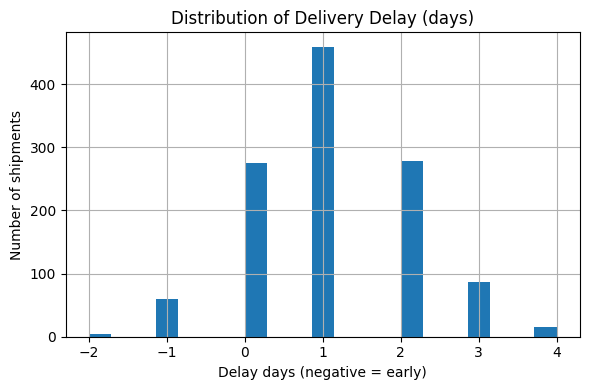

Saved: /content/output/01_delay_distribution.png


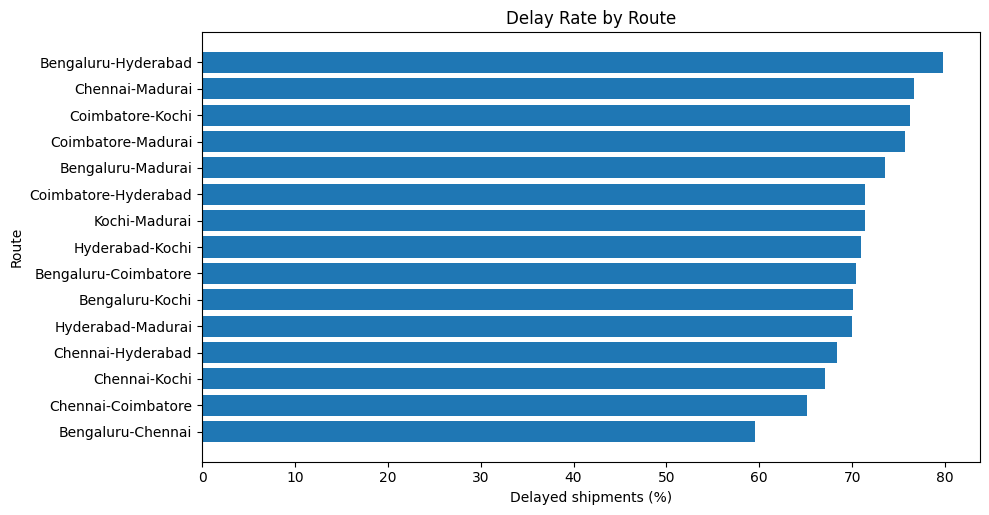

Saved: /content/output/02_delay_by_route.png


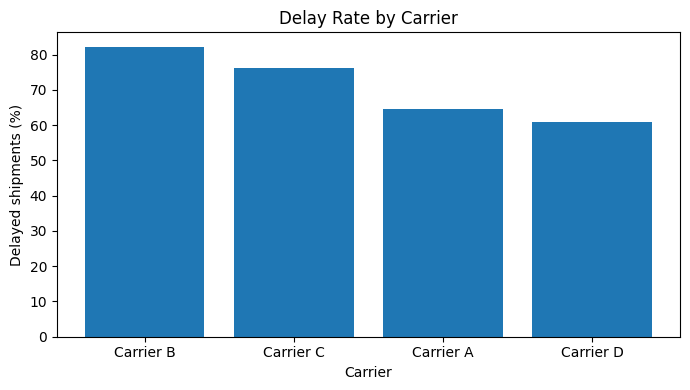

Saved: /content/output/03_delay_by_carrier.png


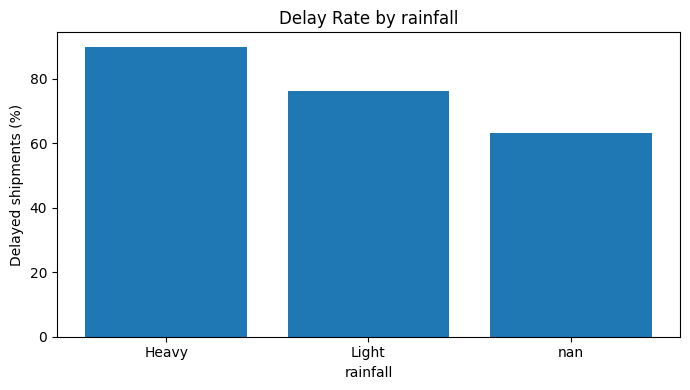

Saved: /content/output/04_delay_by_weather.png


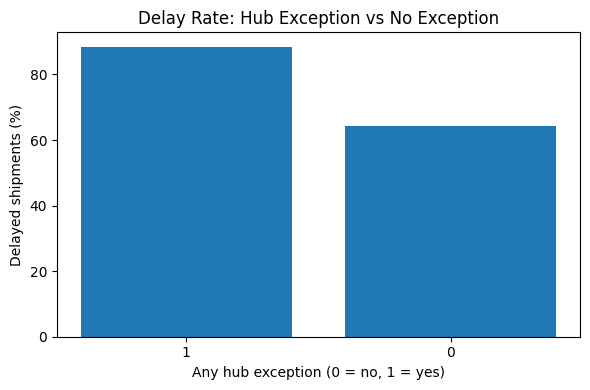

Saved: /content/output/05_delay_by_hub_exception.png


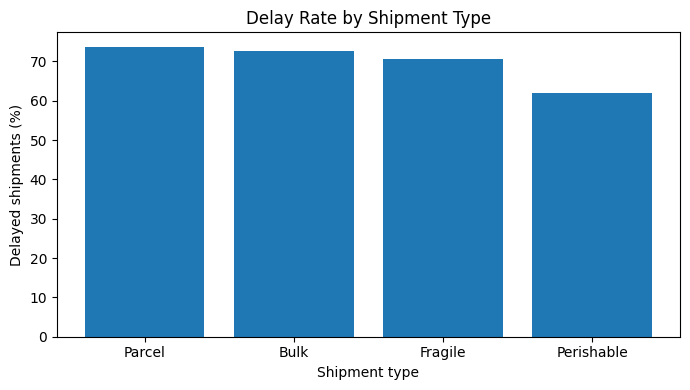

Saved: /content/output/06_delay_by_shipment_type.png


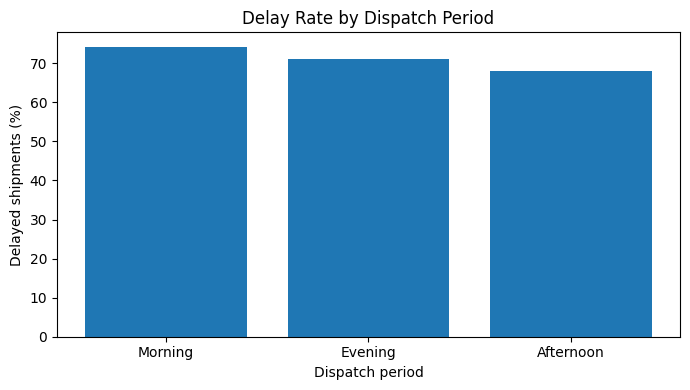

Saved: /content/output/07_delay_by_dispatch_period.png


In [ ]:
# EDA summary table
delivered = master[master["delayed"].notna()].copy()
eda_summary = pd.DataFrame({
    "Metric": [
        "Total cleaned shipments",
        "Shipments with known delivery outcome",
        "Shipments delayed",
        "Delayed shipment rate (%)",
        "Average delay days among late shipments"
    ],
    "Value": [
        len(master),
        len(delivered),
        int((delivered["delayed"] == 1).sum()),
        round((delivered["delayed"].mean() * 100), 2) if len(delivered) else np.nan,
        round(delivered.loc[delivered["delay_days"] > 0, "delay_days"].mean(), 2)
            if (delivered["delay_days"] > 0).any() else 0
    ]
})
display(eda_summary)

def delay_rate_table(group_col, min_count=1):
    if group_col not in delivered.columns:
        print(f"Column not available: {group_col}")
        return pd.DataFrame()
    out = delivered.groupby(group_col, dropna=False).agg(
        shipments=("delayed", "size"),
        delayed_shipments=("delayed", "sum"),
        delay_rate=("delayed", "mean"),
        average_delay_days=("delay_days", "mean")
    ).reset_index()
    out["delay_rate_pct"] = (out["delay_rate"] * 100).round(2)
    out["average_delay_days"] = out["average_delay_days"].round(2)
    return out[out["shipments"] >= min_count].sort_values("delay_rate", ascending=False)

for col in ["route_name", "carrier", "rainfall", "visibility", "storm_flag", "shipment_type", "dispatch_period"]:
    if col in delivered:
        print(f"\nDelay summary by {col}")
        display(delay_rate_table(col))

# Plot helper
def save_plot(filename):
    path = os.path.join(OUTPUT_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", path)

# 1. Delay distribution
plt.figure(figsize=(6,4))
delivered["delay_days"].clip(lower=-5, upper=15).hist(bins=21)
plt.title("Distribution of Delivery Delay (days)")
plt.xlabel("Delay days (negative = early)")
plt.ylabel("Number of shipments")
save_plot("01_delay_distribution.png")

# 2. Delay rate by route
if "route_name" in delivered:
    tab = delay_rate_table("route_name")
    if not tab.empty:
        plt.figure(figsize=(10, max(4, 0.35*len(tab))))
        plt.barh(tab["route_name"].astype(str), tab["delay_rate_pct"])
        plt.title("Delay Rate by Route")
        plt.xlabel("Delayed shipments (%)")
        plt.ylabel("Route")
        plt.gca().invert_yaxis()
        save_plot("02_delay_by_route.png")

# 3. Delay rate by carrier
if "carrier" in delivered:
    tab = delay_rate_table("carrier")
    if not tab.empty:
        plt.figure(figsize=(7,4))
        plt.bar(tab["carrier"].astype(str), tab["delay_rate_pct"])
        plt.title("Delay Rate by Carrier")
        plt.xlabel("Carrier")
        plt.ylabel("Delayed shipments (%)")
        save_plot("03_delay_by_carrier.png")

# 4. Weather and delays
weather_cols = [c for c in ["rainfall", "visibility", "storm_flag"] if c in delivered]
if weather_cols:
    col = weather_cols[0]
    tab = delay_rate_table(col)
    if not tab.empty:
        plt.figure(figsize=(7,4))
        plt.bar(tab[col].astype(str), tab["delay_rate_pct"])
        plt.title(f"Delay Rate by {col}")
        plt.xlabel(col)
        plt.ylabel("Delayed shipments (%)")
        save_plot("04_delay_by_weather.png")

# 5. Hub exceptions
if "any_hub_exception" in delivered:
    tab = delay_rate_table("any_hub_exception")
    if not tab.empty:
        plt.figure(figsize=(6,4))
        plt.bar(tab["any_hub_exception"].astype(str), tab["delay_rate_pct"])
        plt.title("Delay Rate: Hub Exception vs No Exception")
        plt.xlabel("Any hub exception (0 = no, 1 = yes)")
        plt.ylabel("Delayed shipments (%)")
        save_plot("05_delay_by_hub_exception.png")

# 6. Shipment type
if "shipment_type" in delivered:
    tab = delay_rate_table("shipment_type")
    if not tab.empty:
        plt.figure(figsize=(7,4))
        plt.bar(tab["shipment_type"].astype(str), tab["delay_rate_pct"])
        plt.title("Delay Rate by Shipment Type")
        plt.xlabel("Shipment type")
        plt.ylabel("Delayed shipments (%)")
        save_plot("06_delay_by_shipment_type.png")

# 7. Dispatch period
if "dispatch_period" in delivered:
    tab = delay_rate_table("dispatch_period")
    if not tab.empty:
        plt.figure(figsize=(7,4))
        plt.bar(tab["dispatch_period"].astype(str), tab["delay_rate_pct"])
        plt.title("Delay Rate by Dispatch Period")
        plt.xlabel("Dispatch period")
        plt.ylabel("Delayed shipments (%)")
        save_plot("07_delay_by_dispatch_period.png")


## 8. Machine-learning model: predict whether a shipment will be delayed


Features used: ['origin', 'destination', 'route_name', 'carrier', 'service_level', 'shipment_type', 'dispatch_period', 'dispatch_month', 'dispatch_dayofweek', 'dispatch_hour', 'distance_km', 'route_type', 'number_of_hubs', 'rainfall', 'visibility', 'storm_flag']
Target: delayed (1 = delivered after promised date; 0 = on time or early)
Class distribution:


,count
delayed,
1,839
0,339


,model,test_rows,accuracy,precision_delayed,recall_delayed,f1_delayed
0,Random Forest Classifier,295,0.739,0.7854,0.8714,0.8262


               precision    recall  f1-score   support

On time/early       0.56      0.41      0.48        85
      Delayed       0.79      0.87      0.83       210

     accuracy                           0.74       295
    macro avg       0.67      0.64      0.65       295
 weighted avg       0.72      0.74      0.73       295



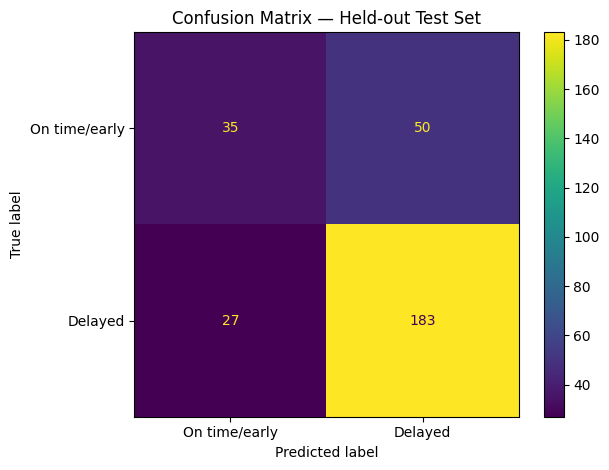

Saved: /content/output/08_model_confusion_matrix.png


In [ ]:
# Prepare rows with known outcomes
model_data = master[master["delayed"].notna()].copy()
model_data["delayed"] = model_data["delayed"].astype(int)

# Candidate features available at dispatch time or from static lookup tables.
candidate_features = [
    "origin", "destination", "route_name", "carrier", "service_level",
    "shipment_type", "dispatch_period", "dispatch_month", "dispatch_dayofweek",
    "dispatch_hour", "distance_km", "route_type", "number_of_hubs",
    "rainfall", "visibility", "storm_flag"
]
features = [c for c in candidate_features if c in model_data.columns]
target = "delayed"

print("Features used:", features)
print("Target: delayed (1 = delivered after promised date; 0 = on time or early)")
print("Class distribution:")
display(model_data[target].value_counts(dropna=False).rename_axis("delayed").to_frame("count"))

if len(features) == 0:
    raise ValueError("No usable model features were found. Check the CSV column names.")
if model_data[target].nunique() < 2:
    print("Model not trained: target has only one class in the known-outcome rows.")
    model_results = pd.DataFrame()
else:
    X = model_data[features].copy()
    y = model_data[target].copy()

    categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric_features = [c for c in X.columns if c not in categorical_features]

    numeric_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features)
    ])

    clf = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=250, random_state=42, class_weight="balanced",
            min_samples_leaf=2
        ))
    ])

    # Stratify only when each class has at least two examples
    stratify_y = y if y.value_counts().min() >= 2 else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=stratify_y
    )
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)

    model_results = pd.DataFrame([{
        "model": "Random Forest Classifier",
        "test_rows": len(y_test),
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "precision_delayed": round(precision_score(y_test, pred, zero_division=0), 4),
        "recall_delayed": round(recall_score(y_test, pred, zero_division=0), 4),
        "f1_delayed": round(f1_score(y_test, pred, zero_division=0), 4)
    }])
    display(model_results)
    print(classification_report(y_test, pred, zero_division=0, target_names=["On time/early", "Delayed"]))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["On time/early", "Delayed"], values_format="d"
    )
    plt.title("Confusion Matrix — Held-out Test Set")
    save_plot("08_model_confusion_matrix.png")


## 9. Explain the model and produce evidence-based findings
The tables below rank groups by observed delay rate. Small groups can be misleading, so always check shipment counts before making recommendations.

In [ ]:
# Exportable breakdown tables
breakdown_tables = {}
for col in ["route_name", "carrier", "rainfall", "visibility", "storm_flag", "shipment_type", "dispatch_period"]:
    if col in delivered.columns:
        breakdown_tables[f"Delay_by_{col[:20]}"] = delay_rate_table(col)

# Add shipment count guardrail to top findings
findings = []
for label, col in [
    ("Route", "route_name"), ("Carrier", "carrier"), ("Rainfall", "rainfall"),
    ("Visibility", "visibility"), ("Storm flag", "storm_flag"),
    ("Shipment type", "shipment_type"), ("Dispatch period", "dispatch_period")
]:
    if col in delivered.columns:
        t = delay_rate_table(col)
        if not t.empty:
            # show the group with the highest observed delay rate, alongside sample size
            r = t.iloc[0]
            findings.append({
                "comparison": label,
                "group_with_highest_observed_delay_rate": str(r[col]),
                "shipments_in_group": int(r["shipments"]),
                "delayed_shipments": int(r["delayed_shipments"]),
                "observed_delay_rate_pct": round(float(r["delay_rate_pct"]), 2),
                "average_delay_days": r["average_delay_days"]
            })
findings_df = pd.DataFrame(findings)
display(findings_df)

print("\nSuggested interpretation template (fill with the observed values above):")
print("1. The highest observed delay rate was for [group], with [n] shipments and a delay rate of [x]%.")
print("2. [Weather/hub/carrier/route factor] had an observed delay rate of [x]% versus [y]% for the comparison group.")
print("3. These are associations in the available dataset, not proof that a factor caused delays.")


,comparison,group_with_highest_observed_delay_rate,shipments_in_group,delayed_shipments,observed_delay_rate_pct,average_delay_days
0,Route,Bengaluru-Hyderabad,89,71,79.78,1.12
1,Carrier,Carrier B,292,240,82.19,1.46
2,Rainfall,Heavy,198,178,89.90,1.73
3,Visibility,Poor,125,112,89.60,1.62
4,Storm flag,1.0,88,84,95.45,1.81
5,Shipment type,Parcel,563,415,73.71,1.12
6,Dispatch period,Morning,442,328,74.21,1.19



Suggested interpretation template (fill with the observed values above):
1. The highest observed delay rate was for [group], with [n] shipments and a delay rate of [x]%.
2. [Weather/hub/carrier/route factor] had an observed delay rate of [x]% versus [y]% for the comparison group.
3. These are associations in the available dataset, not proof that a factor caused delays.


## 10. Export cleaned data, audit, summaries, and charts to Excel
The workbook includes the cleaned master dataset, individual cleaned source tables, quality audit, EDA summaries, group comparisons, findings, and model metrics.

In [ ]:
# Final quality audit
final_quality = []
for name, df in [
    ("shipments_clean", ship_clean), ("routes_clean", routes_clean),
    ("carriers_clean", carriers_clean), ("events_clean", events_clean),
    ("weather_clean", weather_clean), ("master", master)
]:
    final_quality.append({
        "dataset": name, "rows": len(df), "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum())
    })
final_quality_df = pd.DataFrame(final_quality)

# Save CSVs
ship_clean.to_csv(os.path.join(OUTPUT_DIR, "cleaned_shipments.csv"), index=False)
routes_clean.to_csv(os.path.join(OUTPUT_DIR, "cleaned_routes.csv"), index=False)
carriers_clean.to_csv(os.path.join(OUTPUT_DIR, "cleaned_carriers.csv"), index=False)
events_clean.to_csv(os.path.join(OUTPUT_DIR, "cleaned_events.csv"), index=False)
weather_clean.to_csv(os.path.join(OUTPUT_DIR, "cleaned_weather.csv"), index=False)
master.to_csv(os.path.join(OUTPUT_DIR, "master_shipment_analysis.csv"), index=False)

excel_path = os.path.join(OUTPUT_DIR, "Shipment_Delay_Analysis.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    master.to_excel(writer, sheet_name="Master_Data", index=False)
    final_quality_df.to_excel(writer, sheet_name="Quality_Audit", index=False)
    eda_summary.to_excel(writer, sheet_name="Overall_Summary", index=False)
    findings_df.to_excel(writer, sheet_name="Key_Findings", index=False)
    if not model_results.empty:
        model_results.to_excel(writer, sheet_name="Model_Metrics", index=False)
    for sheet, df in breakdown_tables.items():
        safe_sheet = sheet[:31]
        df.to_excel(writer, sheet_name=safe_sheet, index=False)
    ship_clean.to_excel(writer, sheet_name="Clean_Shipments", index=False)
    routes_clean.to_excel(writer, sheet_name="Clean_Routes", index=False)
    carriers_clean.to_excel(writer, sheet_name="Clean_Carriers", index=False)
    events_clean.to_excel(writer, sheet_name="Clean_Events", index=False)
    weather_clean.to_excel(writer, sheet_name="Clean_Weather", index=False)

# Basic worksheet formatting for readability
from openpyxl import load_workbook
wb = load_workbook(excel_path)
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for col_cells in ws.columns:
        max_len = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells[:300])
        ws.column_dimensions[col_cells[0].column_letter].width = min(max(max_len + 2, 12), 35)
wb.save(excel_path)

print("Export complete:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f, "-", os.path.getsize(os.path.join(OUTPUT_DIR, f)), "bytes")


Export complete:
01_delay_distribution.png - 30393 bytes
02_delay_by_route.png - 78415 bytes
03_delay_by_carrier.png - 28678 bytes
04_delay_by_weather.png - 24530 bytes
05_delay_by_hub_exception.png - 29826 bytes
06_delay_by_shipment_type.png - 31827 bytes
07_delay_by_dispatch_period.png - 32713 bytes
08_model_confusion_matrix.png - 40050 bytes
Shipment_Delay_Analysis.xlsx - 330491 bytes
cleaned_carriers.csv - 125 bytes
cleaned_events.csv - 89175 bytes
cleaned_routes.csv - 516 bytes
cleaned_shipments.csv - 180568 bytes
cleaned_weather.csv - 22020 bytes
master_shipment_analysis.csv - 265540 bytes


## 11. Download project outputs
Run this cell to download the Excel workbook, cleaned master CSV, and a ZIP containing all output files and charts.

In [19]:
# Zip the complete output folder for one-click download
zip_path = "/content/Shipment_Delay_Project_Outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(OUTPUT_DIR):
        for file in files:
            full = os.path.join(root, file)
            zf.write(full, arcname=os.path.relpath(full, OUTPUT_DIR))

print("Files are ready in:", OUTPUT_DIR)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("If not using Google Colab, download this file manually:", zip_path)


Files are ready in: /content/output


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Line Chart: Shipment Delay Rate Over Time

import pandas as pd
import matplotlib.pyplot as plt

# Load the shipment dataset
df = pd.read_csv("/content/shipments.csv")

# Check the available columns
print(df.columns.tolist())

['shipment_id', 'origin', 'destination', 'route_name', 'carrier', 'service_level', 'dispatch_datetime', 'promised_delivery_date', 'actual_delivery_date', 'shipment_type', 'dispatch_period', 'weather_id', 'hub_id']


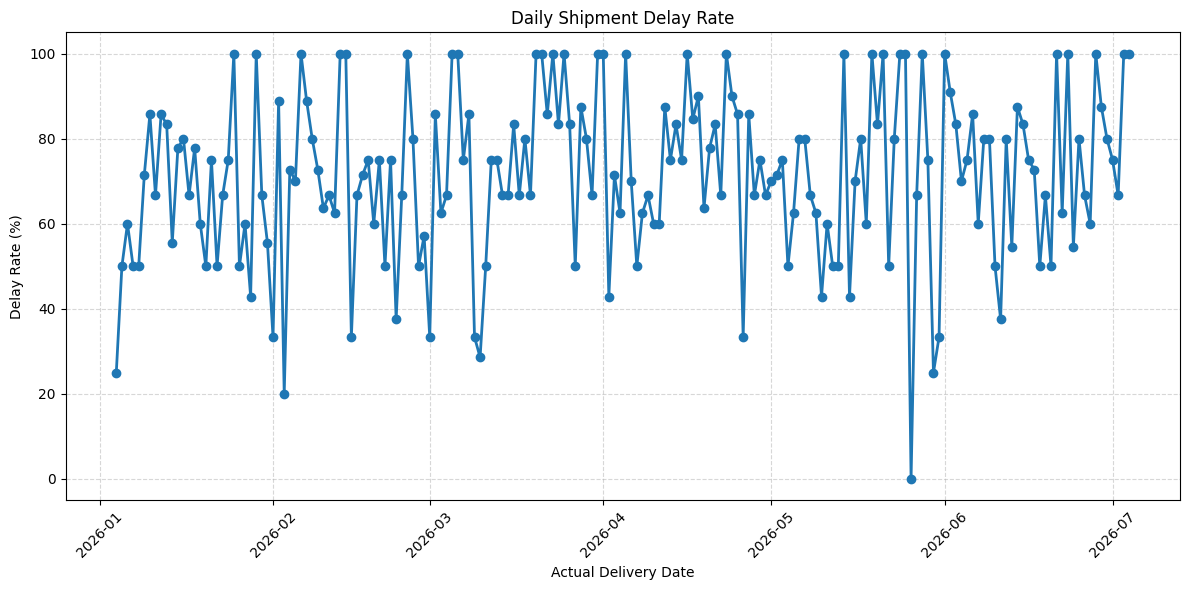

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load shipment dataset
df = pd.read_csv("/content/shipments.csv")

# Convert date columns to datetime
df["actual_delivery_date"] = pd.to_datetime(
    df["actual_delivery_date"], errors="coerce"
)
df["promised_delivery_date"] = pd.to_datetime(
    df["promised_delivery_date"], errors="coerce"
)

# Remove rows with missing delivery dates
df = df.dropna(
    subset=["actual_delivery_date", "promised_delivery_date"]
).copy()

# Identify delayed shipments
df["is_delayed"] = (
    df["actual_delivery_date"] > df["promised_delivery_date"]
)

# Group shipments by actual delivery date
daily_delay = (
    df.groupby(df["actual_delivery_date"].dt.date)["is_delayed"]
    .mean() * 100
)

# Plot line chart
plt.figure(figsize=(12, 6))
plt.plot(
    daily_delay.index,
    daily_delay.values,
    marker="o",
    linewidth=2
)

plt.title("Daily Shipment Delay Rate")
plt.xlabel("Actual Delivery Date")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()